In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
words = open('names.txt').read().splitlines()
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [3]:
chars = sorted(list(set(''.join(words))))
stoi = {c : i+1 for i, c in enumerate(chars)} # create a mapping from character to index, starting from 1
stoi['.'] = 0
itos = {i : c for c, i in stoi.items()}
vocab_size = len(itos)
print(itos)
print(vocab_size)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}
27


In [4]:
# Train split, Val split, Test Split
# build the dataset
block_size = 3 # context length: how many characters do we take to predict the next one?
def build_dataset(words):
    X, Y = [], []
    for w in words:
        
        #print(w)
        context = [0] * block_size
        for ch in w + '.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            #print(''.join(itos[i] for i in context), '--->', itos[ix])
            context = context[1:] + [ix] # crop and append

    X = torch.tensor(X)
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr, Ytr = build_dataset(words[:n1])        # 80%
Xdev, Ydev = build_dataset(words[n1:n2])    # 10%
Xte, Yte = build_dataset(words[n2:])        # 10%

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [5]:
# utility function we will use later when comparing manual gradients to PyTorch gradients
def cmp(s, dt, t):
    ex = torch.all(dt == t.grad).item()
    app = torch.allclose(dt, t.grad)
    maxdiff = (dt - t.grad).abs().max().item()
    print(f'{s:15s} | exact: {str(ex):5s} | approximate: {str(app):5s} | maxdiff: {maxdiff}')


In [6]:
n_embed = 10 # the dimentionality of the character embedding vectors
n_hidden = 64 # the number of neuron in hidden layer
device='cpu'

g = torch.Generator(device=device).manual_seed(2147483647)
C = torch.randn((vocab_size, n_embed),              generator=g, device=device)

W1 = torch.randn((n_embed * block_size, n_hidden),  generator=g, device=device) * (5/3) / ((n_embed * block_size) ** 0.5)
b1 = torch.randn(n_hidden,                          generator=g)                * 0.1

W2 = torch.randn((n_hidden, vocab_size),            generator=g, device=device) * 0.1 # scaling down w2 because logit calculation involves w2. (logits = h @ W2 + b2)
b2 = torch.randn(vocab_size,                        generator=g, device=device) * 0.1

# Initializing this tensors with some values, all zeros can mask an incorrect implementation of backward pass
# Batchnorm params
bn_gain = torch.randn((1, n_hidden), device=device) * 0.1 + 1.0 # batch normalization gain
bn_bias = torch.randn((1, n_hidden), device=device) * 0.1 # batch normalization bias

## At the time of initialization, W1 is initialized roughly unit gaussian so the mean of batch would be roughly zero and std would be roughly one
## so we initialized it the same
bn_mean_running = torch.zeros((1, n_hidden), device=device)
bn_std_running = torch.ones((1, n_hidden), device=device)

parameters = [C, W1, b1, bn_gain, bn_bias, W2, b2]
print(sum(p.nelement() for p in parameters))
for p in parameters:
    p.requires_grad = True


4137


In [7]:
batch_size = 32
n = batch_size
ix = torch.randint(0, Xtr.shape[0], (batch_size, ), generator=g)
Xb, Yb = Xtr[ix], Ytr[ix]

In [8]:
# forward pass
emb = C[Xb]  # embed characters into vectors
emb_cat = emb.view(emb.shape[0], -1)

z1_pre_bn = emb_cat @ W1 + b1 # hidden pre activation

## --------------------------Batch Normalization Layer-----------------------------
bn_mean_i = (1/n) * z1_pre_bn.sum(dim=0, keepdim=True)
bn_diff = z1_pre_bn - bn_mean_i
bn_diff_sq = bn_diff ** 2

bn_var_i = 1/(n-1) * (bn_diff_sq).sum(dim=0, keepdim=True) # Bessel's correction
bn_var_inv = (bn_var_i + 1e-5)**-0.5 # 1/std

bn_raw = bn_diff * bn_var_inv
z1 = bn_gain * bn_raw + bn_bias
# z1 = bn_gain * ((z1_pre_bn - bn_mean_i) / bn_std_i) + bn_bias

## -----------------------------------------------------=--------------------------
h = torch.tanh(z1) # activation

# Layer 2
logits = h @ W2 + b2 # output layer

# loss = F.cross_entropy(logits, Yb)  # loss function
# cross entropy 
logits_maxes = logits.max(dim=1, keepdim=True).values
norm_logits = logits - logits_maxes
counts = norm_logits.exp()
counts_sum = counts.sum(dim=1, keepdim=True)
counts_sum_inv = counts_sum ** -1   # 1/counts_sum
probs = counts * counts_sum_inv
log_probs = probs.log()
loss = -log_probs[range(n), Yb].mean()

# backward pass pytorch
for p in parameters:
    p.grad = None

for t in [log_probs, probs, counts_sum_inv, counts_sum, counts, norm_logits, logits_maxes, logits, 
          h, z1, bn_raw, bn_var_inv, bn_var_i, bn_diff_sq, bn_diff, bn_mean_i, z1_pre_bn, emb_cat, emb]:
    t.retain_grad()

loss.backward()

print(f"Epoch {1} | loss: {loss}")

Epoch 1 | loss: 3.3540592193603516


In [9]:
# Manual gradient calculation

# loss = -(a + b + c) / 3 = -1/3 a + -1/3 b + -1
# d{loss} / d{a} = -1/3 = -1/n
d_log_probs = torch.zeros_like(log_probs)
d_log_probs[range(n), Yb] = -1.0 / n
cmp('log_probs', d_log_probs, log_probs)

# logprobs[i..] = log probs[i..]
# d{logprobs}/d{probs} = 1 / probs
d_probs = (1.0 / probs) * d_log_probs
cmp('probs', d_probs, probs)

# probs = counts * counts_sum_inv 
# d{probs}/d{counts_sum_inv} = counts
# counts: Size([32, 27]), counts_sum_inv: Size([32, 1])
d_counts_sum_inv = (counts * d_probs).sum(dim=1, keepdim=True) # Sum due to broadcast
cmp('counts_sum_inv', d_counts_sum_inv, counts_sum_inv)

# d{loss}/d{probs} * d{probs}/d{counts}
d_counts = counts_sum_inv * d_probs # counts_sum_inv depends on count. 
# This is parial result only, we need to add another derivative of counts to complete its gradient

# counts_sum_inv = counts_sum ** -1   # 1/counts_sum
# Solution: d_counts_sum = (-1.0 / counts_sum ** 2) * d_counts_sum_inv   -> this is also correct
d_counts_sum = (- counts_sum ** -2) * d_counts_sum_inv
cmp('count_sum', d_counts_sum, counts_sum)


# counts_sum = counts.sum(dim=1, keepdim=True)
d_counts += torch.ones_like(counts) * d_counts_sum 
cmp('counts', d_counts, counts)

# counts = norm_logits.exp()
# d{loss}/d{norm_logits} = d{loss}/d{counts} * d{counts}/d{norm_logits}
# Solution: d_norm_logits = norm_logits.exp() * d_counts | counts = norm_logits.exp() 
d_norm_logits = counts * d_counts
cmp('norm_logits', d_norm_logits, norm_logits)

# norm_logits.shape:  torch.Size([32, 27]) logits.shape:  torch.Size([32, 27]) logits_maxes.shape:  torch.Size([32, 1])
# norm_logits = logits - logits_maxes
# d{loss}/d{logit_maxes} = d{loss}/d{norm_logits} * d{norn_logits}/d{logits_maxes}
'''
# c11 c12 c13 = a11 a12 a13     b1  | b1=max(a11, a12, a13)
# c21 c22 c23 = a21 a22 a23  -  b2  | b2=max(a21, a22, a23)
# c31 c32 c33 = a31 a32 a33     b3  | b3=max(a31, a32, a33)

# so e.g. c32 = a32 - b3

'''

d_logits_maxes = (-d_norm_logits).sum(dim=1, keepdim=True) # = -torch.ones_like(logits_maxes) * d_norm_logits.sum(dim=1, keepdim=True)
cmp('logits_maxes', d_logits_maxes, logits_maxes)

# d{loss}/d{logits} = d{loss}/d{norm_logits} * d{norm_logits}/d{logits} + d{loss}/d{logits_maxes} * d{logits_maxes}/d{logits}
# norm_logits = logits - logits_maxes
d_logits = d_norm_logits.clone() # = torch.ones_like(norm_logits) * d_norm_logits

# logits_maxes = logits.max(dim=1, keepdim=True).values
d_logits += F.one_hot(logits.max(dim=1).indices, num_classes=logits.shape[1]) * d_logits_maxes # d_logit_max is allowed to flow back from the location where the max of that row occured
cmp('logits', d_logits, logits)

# z1.shape:         [32, 64] 
# W2.shape          [64, 27] 
# b2.shape          [    27]
# h.shape           [32, 64] 

# logits = h @ W2 + b2 # output layer
# [32, 27] = [32, 64]@[64, 27] + [27]
d_h = d_logits @ W2.T
cmp('h', d_h, h)

d_W2 = h.T @ d_logits
cmp('W2', d_W2, W2)

d_b2 = d_logits.sum(dim=0)
cmp('b2', d_b2, b2)


# h = torch.tanh(z1) # activation
# d{loss}/d{z1} = d{loss}/d{h} * d{h}/d{z1}
# d{tanh(x)}/d{x} = 1 - [tanh(x)]**2  & h = tanh(x) => 1 - [h]**2 == local gradient
d_z1 = (1.0 - h ** 2) * d_h
cmp('z1', d_z1, z1)

# z1        : [32, 64]
# bn_gain   : [1, 64] 
# bn_raw    : [32, 64] 
# bn_bias   : [1, 64]
# z1 = bn_gain * bn_raw + bn_bias
d_bn_raw = bn_gain * d_z1
cmp('bn_raw', d_bn_raw, bn_raw)

d_bn_gain = (bn_raw * d_z1).sum(dim=0, keepdim=True)
cmp('bn_gain', d_bn_gain, bn_gain)

d_bn_bias = (d_z1).sum(dim=0, keepdim=True)
cmp('bn_bias', d_bn_bias, bn_bias)

# bn_raw = bn_diff * bn_var_inv
d_bn_var_inv = (bn_diff * d_bn_raw).sum(dim=0, keepdim=True)
cmp('bn_var_inv', d_bn_var_inv, bn_var_inv)


# bn_var_inv = (bn_var_i + 1e-5)**-0.5   # d{(x)^k} = k * (x)^(k-1) & d{(bn_var_i + 1e-5)} = 1  <-- product rule
d_bn_var_i = (-0.5 * (bn_var_i + 1e-5) ** -1.5) * 1 * d_bn_var_inv
cmp('bn_var_i', d_bn_var_i, bn_var_i)


# bn_var_i:
# bn_var_i_1
# bn_var_i_2

# bn_diff_sq:
# bn_diff_sq_11    bn_diff_sq_12
# bn_diff_sq_21    bn_diff_sq_22

# d_bn_diff_sq:
# d{bn_var_i_1}/d{bn_diff_sq_11} * d_bn_var_i_1 + d{bn_var_i_2}/d{bn_diff_sq_11} * d_bn_var_i_2,       d{bn_var_i_1}/d{bn_diff_sq_12} * d_bn_var_i_1 + d{bn_var_i_2}/d{bn_diff_sq_12} * d_bn_var_i_2
# d{bn_var_i_1}/d{bn_diff_sq_21} * d_bn_var_i_1 + d{bn_var_i_2}/d{bn_diff_sq_21} * d_bn_var_i_2,       d{bn_var_i_1}/d{bn_diff_sq_22} * d_bn_var_i_1 + d{bn_var_i_2}/d{bn_diff_sq_22} * d_bn_var_i_2
# --->
# 
# # we know
# bn_var_i_1 = 1/(n-1)*(bn_diff_sq_11 + bn_diff_sq_21)
# bn_var_i_2 = 1/(n-1)*(bn_diff_sq_12 + bn_diff_sq_22)

# d{bn_var_i_1}/d{bn_diff_sq_11} = 1/(n-1) * 1
# d{bn_var_i_1}/d{bn_diff_sq_21} = 1/(n-1) * 1
# d{bn_var_i_2}/d{bn_diff_sq_11} = 1/(n-1) * 0
# d{bn_var_i_2}/d{bn_diff_sq_21} = 1/(n-1) * 0
# d{bn_var_i_1}/d{bn_diff_sq_12} = 1/(n-1) * 0
# d{bn_var_i_1}/d{bn_diff_sq_22} = 1/(n-1) * 0
# d{bn_var_i_2}/d{bn_diff_sq_12} = 1/(n-1) * 1
# d{bn_var_i_2}/d{bn_diff_sq_22} = 1/(n-1) * 1

# d_bn_diff_sq:
# 1/(n-1) * d_bn_var_i_1 + 0 * d_bn_var_i_2,      0 * d_bn_var_i_1 + 1/(n-1) * d_bn_var_i_2
# 1/(n-1) * d_bn_var_i_1 + 0 * d_bn_var_i_2,      0 * d_bn_var_i_1 + 1/(n-1) * d_bn_var_i_2
# ==

# d_bn_diff_sq:
# 1/(n-1) * d_bn_var_i_1,    1/(n-1) * d_bn_var_i_2
# 1/(n-1) * d_bn_var_i_1,    1/(n-1) * d_bn_var_i_2

# d_bn_diff_sq:
# [1/(n-1),  1/(n-1)]  *  [d_bn_var_i_1,   d_bn_var_i_2]
# [1/(n-1),  1/(n-1)]  *  [d_bn_var_i_1,   d_bn_var_i_2]

# bn_var_i = 1/(n-1) * (bn_diff_sq).sum(dim=0, keepdim=True)
d_bn_diff_sq = (1.0/(n-1) * torch.ones_like(bn_diff_sq)) * d_bn_var_i
cmp('bn_diff_sq', d_bn_diff_sq, bn_diff_sq)


# bn_raw = bn_diff * bn_var_inv
d_bn_diff = bn_var_inv * d_bn_raw
# bn_diff_sq = bn_diff ** 2
d_bn_diff += 2 * bn_diff * d_bn_diff_sq
cmp('bn_diff', d_bn_diff, bn_diff)

# bn_diff = z1_pre_bn - bn_mean_i
d_bn_mean_i = (-d_bn_diff).sum(dim=0, keepdim=True)
cmp('bn_mean_i', d_bn_mean_i, bn_mean_i)


# bn_diff = z1_pre_bn - bn_mean_i
d_z1_pre_bn = d_bn_diff.clone()
# bn_mean_i = (1/n) * z1_pre_bn.sum(dim=0, keepdim=True)
d_z1_pre_bn += (1.0/n) * torch.ones_like(z1_pre_bn) * d_bn_mean_i
cmp('z1_pre_bn', d_z1_pre_bn, z1_pre_bn) 

# emb_cat: [32, 30] 
# W1     : [30, 64] 
# b1     : [    64] 
# z1:    : [32, 64] 
# z1_pre_bn = emb_cat @ W1 + b1 # hidden pre activation
d_emb_cat = d_z1_pre_bn @ W1.T
cmp('emb_cat', d_emb_cat, emb_cat) 

d_W1 = emb_cat.T @ d_z1_pre_bn
cmp('W1', d_W1, W1) 

d_b1 = d_z1_pre_bn.sum(dim=0)
cmp('b1', d_b1, b1) 

# emb_cat = emb.view(emb.shape[0], -1)
# d_emb = d_emb_cat.view(-1, block_size, n_embed) <-- this is also correct
d_emb = d_emb_cat.view(emb.shape)
cmp('emb', d_emb, emb)

# emb: [32, 3, 10] 
# Xb : [32, 3] 
# C  : [27, 10]
# emb = C[Xb]  # embed characters into vector
dC = torch.zeros_like(C)
for i in range(Xb.shape[0]):
    for j in range(Xb.shape[1]):
        ix = Xb[i][j]
        dC[ix] += d_emb[i, j] # vector with 10 elements = vector with 10 elements

cmp('C', dC, C)
 

log_probs       | exact: True  | approximate: True  | maxdiff: 0.0
probs           | exact: True  | approximate: True  | maxdiff: 0.0
counts_sum_inv  | exact: True  | approximate: True  | maxdiff: 0.0
count_sum       | exact: True  | approximate: True  | maxdiff: 0.0
counts          | exact: True  | approximate: True  | maxdiff: 0.0
norm_logits     | exact: True  | approximate: True  | maxdiff: 0.0
logits_maxes    | exact: True  | approximate: True  | maxdiff: 0.0
logits          | exact: True  | approximate: True  | maxdiff: 0.0
h               | exact: True  | approximate: True  | maxdiff: 0.0
W2              | exact: True  | approximate: True  | maxdiff: 0.0
b2              | exact: True  | approximate: True  | maxdiff: 0.0
z1              | exact: True  | approximate: True  | maxdiff: 0.0
bn_raw          | exact: True  | approximate: True  | maxdiff: 0.0
bn_gain         | exact: True  | approximate: True  | maxdiff: 0.0
bn_bias         | exact: True  | approximate: True  | maxdiff:

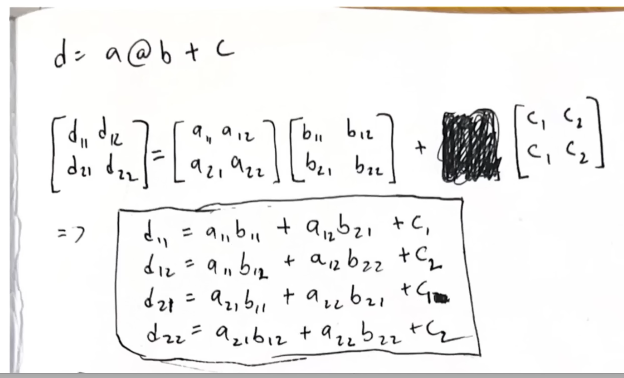

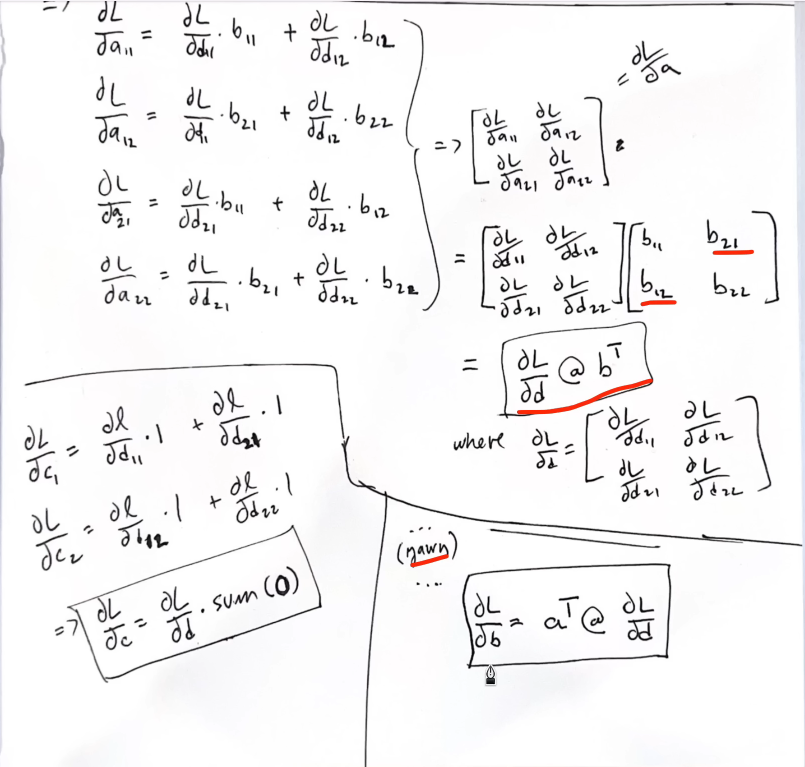

In [10]:
print(counts.shape, counts_sum_inv.shape)
print(counts.shape, counts_sum.shape)
print("norm_logits.shape: ", norm_logits.shape, "logits.shape: ", logits.shape, "logits_maxes.shape: ", logits_maxes.shape)
print("logits.max(dim=1, keepdim=True).indices.shape", logits.max(dim=1, keepdim=True).indices.shape)
print("emb_cat.shape:", emb_cat.shape, "z1.shape:", z1.shape, "h.shape", h.shape, "W1.shape", W1.shape, "b1.shape", b1.shape, "W2.shape", W2.shape, "b2.shape", b2.shape)
print("bn_gain:", bn_gain.shape, "\nbn_raw:", bn_raw.shape, "\nbn_bias:", bn_bias.shape)
print("bn_diff:", bn_diff.shape) 
print("bn_var_inv:", bn_var_inv.shape) 
print("emb: ", emb.shape, "\nXb:", Xb.shape, "\nC:", C.shape)

torch.Size([32, 27]) torch.Size([32, 1])
torch.Size([32, 27]) torch.Size([32, 1])
norm_logits.shape:  torch.Size([32, 27]) logits.shape:  torch.Size([32, 27]) logits_maxes.shape:  torch.Size([32, 1])
logits.max(dim=1, keepdim=True).indices.shape torch.Size([32, 1])
emb_cat.shape: torch.Size([32, 30]) z1.shape: torch.Size([32, 64]) h.shape torch.Size([32, 64]) W1.shape torch.Size([30, 64]) b1.shape torch.Size([64]) W2.shape torch.Size([64, 27]) b2.shape torch.Size([27])
bn_gain: torch.Size([1, 64]) 
bn_raw: torch.Size([32, 64]) 
bn_bias: torch.Size([1, 64])
bn_diff: torch.Size([32, 64])
bn_var_inv: torch.Size([1, 64])
emb:  torch.Size([32, 3, 10]) 
Xb: torch.Size([32, 3]) 
C: torch.Size([27, 10])


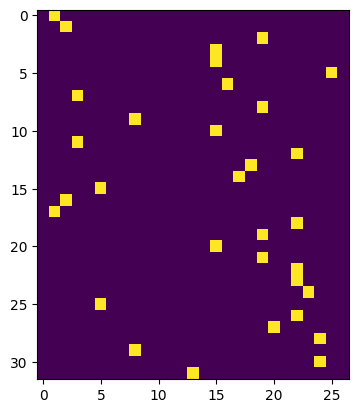

In [11]:
plt.imshow(F.one_hot(logits.max(dim=1).indices, num_classes=logits.shape[1]))

In [12]:
log_probs[range(n), Yb]

tensor([-4.1271, -3.0975, -3.6838, -3.3299, -4.1418, -3.5360, -3.1236, -4.0756,
        -3.1901, -4.1767, -3.0577, -1.6977, -2.8548, -3.0570, -3.0212, -3.2330,
        -3.8254, -3.0907, -3.4991, -3.4025, -2.7908, -3.0895, -4.2348, -3.8942,
        -3.5252, -2.8333, -2.9943, -3.9790, -2.8449, -3.4208, -3.4160, -3.0857],
       grad_fn=<IndexBackward0>)

In [13]:
# Exercise 2: backprop through cross_entropy but all in one go
# to complete this challenge look at the mathematical expression of the loss,
# take the derivative, simplify the expression, and just write it out

# forward pass

# before:
# logits_maxes = logits.max(dim=1, keepdim=True).values
# norm_logits = logits - logits_maxes
# counts = norm_logits.exp()
# counts_sum = counts.sum(dim=1, keepdim=True)
# counts_sum_inv = counts_sum ** -1   # 1/counts_sum
# probs = counts * counts_sum_inv
# log_probs = probs.log()
# loss = -log_probs[range(n), Yb].mean()

#Now:
loss_fast = F.cross_entropy(logits, Yb)
print(loss_fast.item(), ' diff', (loss_fast - loss).item())



3.3540596961975098  diff 4.76837158203125e-07


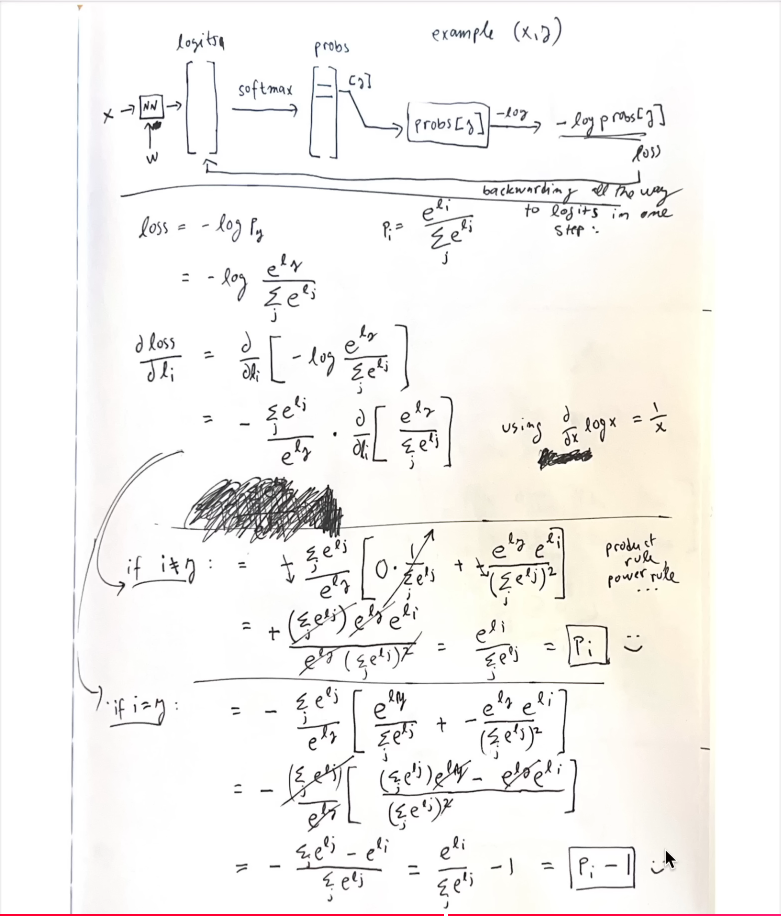

In [14]:
# Fast backward pass

d_logits = F.softmax(logits, dim=1) # this is calculating pi for each element
d_logits[range(n), Yb] -= 1         # substracting 1 from each correct pl and this is the d{logits}
d_logits /= n                       # mean

cmp('logits', d_logits, logits)

logits          | exact: False | approximate: True  | maxdiff: 6.51925802230835e-09


In [15]:
F.softmax(logits, dim=1)[0]

tensor([0.0617, 0.0868, 0.0191, 0.0507, 0.0197, 0.0862, 0.0246, 0.0325, 0.0161,
        0.0321, 0.0365, 0.0327, 0.0354, 0.0297, 0.0344, 0.0139, 0.0082, 0.0208,
        0.0160, 0.0567, 0.0539, 0.0227, 0.0222, 0.0739, 0.0618, 0.0293, 0.0225],
       grad_fn=<SelectBackward0>)

In [16]:
d_logits[0] * n

tensor([ 0.0617,  0.0868,  0.0191,  0.0507,  0.0197,  0.0862,  0.0246,  0.0325,
        -0.9839,  0.0321,  0.0365,  0.0327,  0.0354,  0.0297,  0.0344,  0.0139,
         0.0082,  0.0208,  0.0160,  0.0567,  0.0539,  0.0227,  0.0222,  0.0739,
         0.0618,  0.0293,  0.0225], grad_fn=<MulBackward0>)

In [17]:
Yb[0]

tensor(8)

We can see that in the d_logits, value of correct index is negative others are positive .

We can think of d_logits as a force by which we are going to pulling down the probabilities of logits. 

For correct index, it is negative that means it will be pushed up.

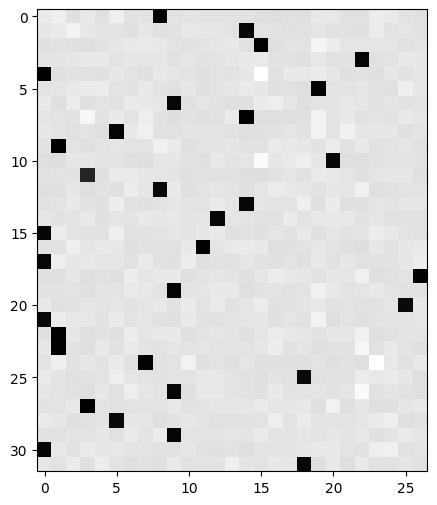

In [18]:
plt.figure(figsize=(6, 6))
plt.imshow(d_logits.detach(), cmap='gray');

In [19]:
# Exercise 3: backprop through batchnorm but all in one go
# to complete this challenge look at the mathematical expression of the output of batchnorm,
# take the derivative w.r.t. its input, simplify the expression, and just write it out
# 
# forward pass
# 
# before:
# z1_pre_bn = emb_cat @ W1 + b1 # hidden pre activation

# ## --------------------------Batch Normalization Layer-----------------------------
# bn_mean_i = (1/n) * z1_pre_bn.sum(dim=0, keepdim=True)
# bn_diff = z1_pre_bn - bn_mean_i
# bn_diff_sq = bn_diff ** 2

# bn_var_i = 1/(n-1) * (bn_diff_sq).sum(dim=0, keepdim=True) # Bessel's correction
# bn_var_inv = (bn_var_i + 1e-5)**-0.5 # 1/std

# bn_raw = bn_diff * bn_var_inv
# z1 = bn_gain * bn_raw + bn_bias

# now fast
z1_fast = bn_gain * ((z1_pre_bn - z1_pre_bn.mean(dim=0, keepdim=True)) / z1_pre_bn.std(dim=0, keepdim=True)) + bn_bias
print('max diff:', (z1_fast - z1).abs().max())

max diff: tensor(3.1948e-05, grad_fn=<MaxBackward1>)


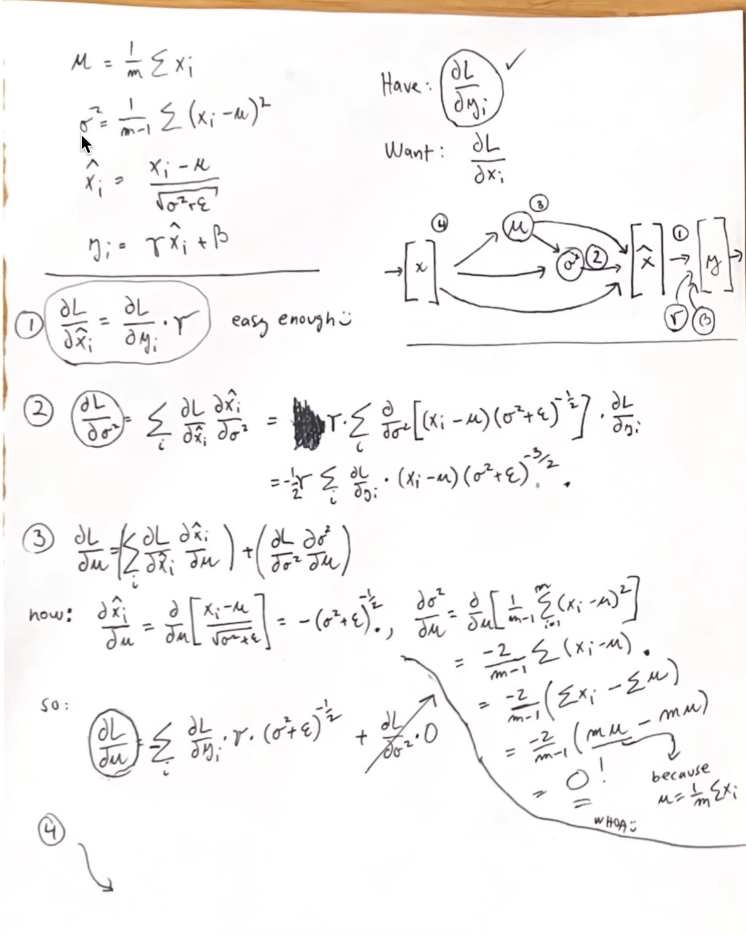

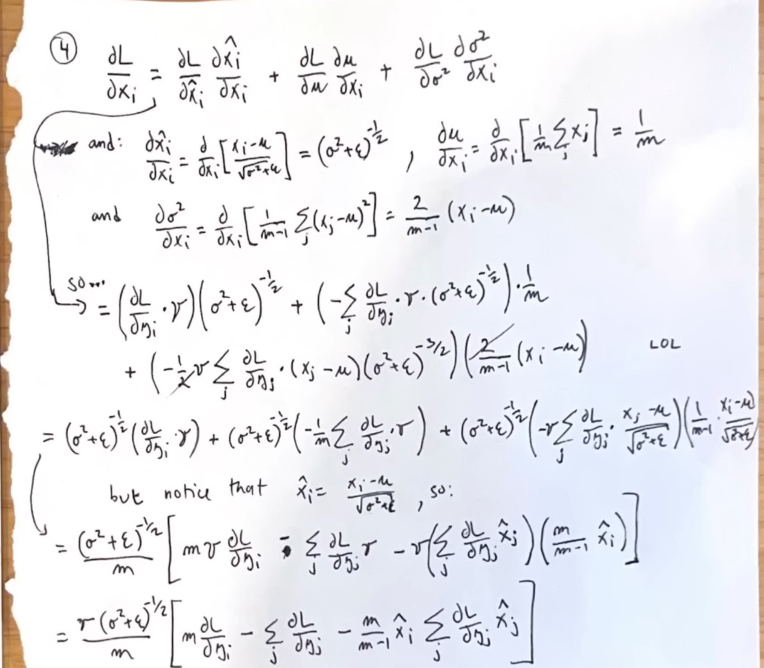

In [21]:
# backwar pass

# before
# d_z1 = (1.0 - h ** 2) * d_h
# d_bn_raw = bn_gain * d_z1
# d_bn_var_inv = (bn_diff * d_bn_raw).sum(dim=0, keepdim=True)
# d_bn_var_i = (-0.5 * (bn_var_i + 1e-5) ** -1.5) * 1 * d_bn_var_inv
# d_bn_diff_sq = (1.0/(n-1) * torch.ones_like(bn_diff_sq)) * d_bn_var_i
# d_bn_diff = bn_var_inv * d_bn_raw
# d_bn_diff += 2 * bn_diff * d_bn_diff_sq
# d_bn_mean_i = (-d_bn_diff).sum(dim=0, keepdim=True)
# d_z1_pre_bn = d_bn_diff.clone()
# d_z1_pre_bn += (1.0/n) * torch.ones_like(z1_pre_bn) * d_bn_mean_i


# calculate d_z1_pre_bn given d_z1(i.e backprop through batch norm)
# you will need to use some variables from the forward pass up above
d_z1_pre_bn = bn_gain * bn_var_inv/n * (n*d_z1 - d_z1.sum(dim=0) - n/(n-1)*bn_raw*(d_z1*bn_raw).sum(dim=0))
cmp('z1_pre_bn', d_z1_pre_bn, z1_pre_bn)


z1_pre_bn       | exact: False | approximate: True  | maxdiff: 9.313225746154785e-10


In [30]:
## Everything at one place
n_embed = 10 # the dimentionality of the character embedding vectors
n_hidden = 64 # the number of neuron in hidden layer
device='cpu'

g = torch.Generator(device=device).manual_seed(2147483647)
C = torch.randn((vocab_size, n_embed),              generator=g, device=device)

W1 = torch.randn((n_embed * block_size, n_hidden),  generator=g, device=device) * (5/3) / ((n_embed * block_size) ** 0.5)
b1 = torch.randn(n_hidden,                          generator=g)                * 0.1

W2 = torch.randn((n_hidden, vocab_size),            generator=g, device=device) * 0.1 # scaling down w2 because logit calculation involves w2. (logits = h @ W2 + b2)
b2 = torch.randn(vocab_size,                        generator=g, device=device) * 0.1

# Initializing this tensors with some values, all zeros can mask an incorrect implementation of backward pass
# Batchnorm params
bn_gain = torch.randn((1, n_hidden), device=device) * 0.1 + 1.0 # batch normalization gain
bn_bias = torch.randn((1, n_hidden), device=device) * 0.1 # batch normalization bias

## At the time of initialization, W1 is initialized roughly unit gaussian so the mean of batch would be roughly zero and std would be roughly one
## so we initialized it the same
bn_mean_running = torch.zeros((1, n_hidden), device=device)
bn_std_running = torch.ones((1, n_hidden), device=device)

parameters = [C, W1, b1, bn_gain, bn_bias, W2, b2]
print(sum(p.nelement() for p in parameters))
for p in parameters:
    p.requires_grad = True


batch_size = 32
n = batch_size
max_steps = 200000
lossi = []

4137


In [31]:
with torch.no_grad():
    for epoch in range(max_steps):
        ix = torch.randint(0, Xtr.shape[0], (batch_size, ), generator=g)
        Xb, Yb = Xtr[ix], Ytr[ix]
        # forward pass
        emb = C[Xb]  # embed characters into vectors
        emb_cat = emb.view(emb.shape[0], -1)

        z1_pre_bn = emb_cat @ W1 + b1 # hidden pre activation

        ## --------------------------Batch Normalization Layer-----------------------------
        bn_mean_i = (1/n) * z1_pre_bn.sum(dim=0, keepdim=True)
        bn_diff = z1_pre_bn - bn_mean_i
        bn_diff_sq = bn_diff ** 2

        bn_var_i = 1/(n-1) * (bn_diff_sq).sum(dim=0, keepdim=True) # Bessel's correction
        bn_var_inv = (bn_var_i + 1e-5)**-0.5 # 1/std

        bn_raw = bn_diff * bn_var_inv
        z1 = bn_gain * bn_raw + bn_bias
        # z1 = bn_gain * ((z1_pre_bn - bn_mean_i) / bn_std_i) + bn_bias

        ## -----------------------------------------------------=--------------------------
        h = torch.tanh(z1) # activation

        # Layer 2
        logits = h @ W2 + b2 # output layer

        # loss = F.cross_entropy(logits, Yb)  # loss function
        # cross entropy 
        logits_maxes = logits.max(dim=1, keepdim=True).values
        norm_logits = logits - logits_maxes
        counts = norm_logits.exp()
        counts_sum = counts.sum(dim=1, keepdim=True)
        counts_sum_inv = counts_sum ** -1   # 1/counts_sum
        probs = counts * counts_sum_inv
        log_probs = probs.log()
        loss = -log_probs[range(n), Yb].mean()

        # backward pass pytorch
        # for p in parameters:
        #     p.grad = None

        # for t in [log_probs, probs, counts_sum_inv, counts_sum, counts, norm_logits, logits_maxes, logits, 
        #         h, z1, bn_raw, bn_var_inv, bn_var_i, bn_diff_sq, bn_diff, bn_mean_i, z1_pre_bn, emb_cat, emb]:
        #     t.retain_grad()

        # loss.backward()
        # Cross entrpy
        d_logits = F.softmax(logits, dim=1) # this is calculating pi for each element
        d_logits[range(n), Yb] -= 1         # substracting 1 from each correct pl and this is the d{logits}
        d_logits /= n

        # layer 2
        d_h = d_logits @ W2.T
        d_W2 = h.T @ d_logits
        d_b2 = d_logits.sum(dim=0)

        # tanh
        d_z1 = (1.0 - h ** 2) * d_h

        # batch norm
        d_bn_gain = (bn_raw * d_z1).sum(dim=0, keepdim=True)
        d_bn_bias = (d_z1).sum(dim=0, keepdim=True)
        d_z1_pre_bn = bn_gain * bn_var_inv/n * (n*d_z1 - d_z1.sum(dim=0) - n/(n-1)*bn_raw*(d_z1*bn_raw).sum(dim=0))
        # 1st layer
        d_emb_cat = d_z1_pre_bn @ W1.T
        d_W1 = emb_cat.T @ d_z1_pre_bn
        d_b1 = d_z1_pre_bn.sum(dim=0)

        # embedding
        d_emb = d_emb_cat.view(emb.shape)

        d_C = torch.zeros_like(C)
        for i in range(Xb.shape[0]):
            for j in range(Xb.shape[1]):
                ix = Xb[i][j]
                d_C[ix] += d_emb[i, j] # vector with 10 elements = vector with 10 elements
        # parameters = [C, W1, b1, bn_gain, bn_bias, W2, b2]
        grads = [d_C, d_W1, d_b1, d_bn_gain, d_bn_bias, d_W2, d_b2]

        # update 
        lr = 0.1 if epoch < 100000 else 0.01

        for p, grad in zip(parameters, grads):
            # p.data += -lr * p.grad
            p.data += -lr * grad
        if epoch % 10000 == 0:
            print(f"Epoch {epoch} | loss: {loss}")
        lossi.append(loss.log10().item())

Epoch 0 | loss: 3.344012498855591
Epoch 10000 | loss: 2.4410629272460938
Epoch 20000 | loss: 2.1605148315429688
Epoch 30000 | loss: 2.3773670196533203
Epoch 40000 | loss: 2.3037633895874023
Epoch 50000 | loss: 2.0802876949310303
Epoch 60000 | loss: 2.286369800567627
Epoch 70000 | loss: 2.4214744567871094
Epoch 80000 | loss: 2.176229238510132
Epoch 90000 | loss: 2.3219547271728516
Epoch 100000 | loss: 2.050239086151123
Epoch 110000 | loss: 1.8946648836135864
Epoch 120000 | loss: 1.9407261610031128
Epoch 130000 | loss: 2.66243314743042
Epoch 140000 | loss: 1.8202695846557617
Epoch 150000 | loss: 2.225740432739258
Epoch 160000 | loss: 2.0296826362609863
Epoch 170000 | loss: 2.2651596069335938
Epoch 180000 | loss: 1.9797780513763428
Epoch 190000 | loss: 1.9861887693405151


In [26]:
for p, g in zip(parameters, grads):
        cmp(str(tuple(p.shape)), g, p)

(27, 10)        | exact: False | approximate: True  | maxdiff: 1.4901161193847656e-08
(30, 64)        | exact: False | approximate: True  | maxdiff: 1.4901161193847656e-08
(64,)           | exact: False | approximate: True  | maxdiff: 4.6566128730773926e-09
(1, 64)         | exact: False | approximate: True  | maxdiff: 4.190951585769653e-09
(1, 64)         | exact: False | approximate: True  | maxdiff: 9.313225746154785e-09
(64, 27)        | exact: False | approximate: True  | maxdiff: 1.5832483768463135e-08
(27,)           | exact: False | approximate: True  | maxdiff: 1.4901161193847656e-08


In [ ]:
# calculate the batch norm at the end of training 
with torch.no_grad():
    emb = C[Xtr]
    emb_cat = emb.view(emb.shape[0], -1)
    z = emb_cat @ W1 + b1
    bn_mean = z.mean(dim=0, keepdim = True)
    bn_std = z.std(dim=0, keepdim = True)

In [ ]:
splits = {
    'train': (Xtr, Ytr),
    'val': (Xdev, Ydev),
    'test': (Xte, Yte),
}

@torch.no_grad() # disable gradient tracking
def split_loss(split):
    x, y = splits[split]
    emb = C[x]  # (N, block_size, n_embed). block_size=context length
    emb_cat = emb.view(emb.shape[0], -1) # (N, block_size * n_embed)
    z1 = emb_cat @ W1 #+ b1 # (N, n_hidden)
    z1 = bn_gain * ((z1 - bn_mean) / bn_std) + bn_bias
    h = torch.tanh(z1) # (N, n_hidden)
    logits = h @ W2 + b2 # (N, vocab_size)
    loss = F.cross_entropy(logits, y)
    print(split, loss.item())

split_loss('train')
split_loss('val')

In [ ]:
# sample from the model
g = torch.Generator().manual_seed(2147483647 + 10)
with torch.no_grad():
    for _ in range(20):
        out = []
        context = [0] * block_size # initialize with all ...
        while True:
            # forward pass
            emb = C[torch.tensor([context])] # (1, block_size, n_embed)
            h = torch.tanh(emb.view(1, -1) @ W1 + b1)
            logits = h @ W2 + b2
            probs = F.softmax(logits, dim=1)
            # sample from the distribution
            ix = torch.multinomial(probs, num_samples=1, generator=g).item()
            context = context[1:] + [ix]
            out.append(ix)
            if ix == 0:
                break
                
        print(''.join(itos[i] for i in out))